# Honest two-dimensional maps

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/14-maps.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/14-maps.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `68d00a522f1acaff4fd3f2dd622319e6ed0b2d7be543b28d03d1c3ae0735df0c`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Honest two-dimensional maps

**Lesson 14 · Original synthetic data · Independent educational project**

## Objectives

Use fixed color limits across time; separate rendering choices from physical change.

[Previous](13-verification.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/14-maps.ipynb) · [Next](15-projections.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=14-maps.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

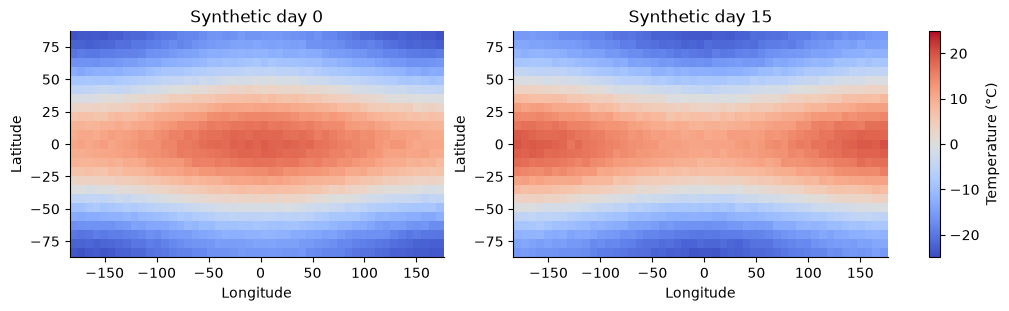

Both frames use the same -25 to 25 °C scale


In [2]:
cube = lab.synthetic_cube()
days = [0, 15]
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for ax, day in zip(axes, days):
    field = cube["temperature"][day]-273.15
    im = ax.pcolormesh(cube["lon"], cube["lat"], field, vmin=-25, vmax=25, cmap="coolwarm", shading="auto")
    ax.set(title=f"Synthetic day {day}", xlabel="Longitude", ylabel="Latitude")
fig.colorbar(im, ax=axes, label="Temperature (°C)")
plt.show()
assert axes[0].collections[0].get_clim() == axes[1].collections[0].get_clim()
print("Both frames use the same -25 to 25 °C scale")

## Exercise

Render each frame using automatic color limits and compare the story the two versions appear to tell.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interactive Lab experiment

Move the time slider, change the variable or rotate the 3D view. This widget runs in a Python kernel in Lab; the published book preserves a static output. Explain which control changes the data and which only changes its display.

In [ ]:
import ipywidgets as widgets
from IPython.display import display
interactive_cube = lab.synthetic_cube(nlat=19, nlon=31)
def explore(day=0, variable="temperature", azimuth=-55):
    units = interactive_cube["units"][variable]
    field = interactive_cube[variable][day]
    bounds = (245, 300) if variable == "temperature" else (0, 8)
    fig = plt.figure(figsize=(8, 4))
    ax = fig.add_subplot()
    im = ax.pcolormesh(interactive_cube["lon"], interactive_cube["lat"], field, shading="auto", vmin=bounds[0], vmax=bounds[1])
    fig.colorbar(im, ax=ax, label=units)
    ax.set(xlabel="Longitude", ylabel="Latitude")
    fig.suptitle(f"Synthetic {variable}, day {day}")
    plt.tight_layout(); plt.show()
controls = widgets.interactive(explore, day=widgets.IntSlider(min=0,max=59,value=0),
                               variable=["temperature", "precipitation"], azimuth=widgets.fixed(-55))
display(controls)

## Interpretation and limits

This equirectangular display stretches areas toward the poles. It is useful for coordinates but not for judging geographic area by eye.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://matplotlib.org/stable/users/explain/colors/colormaps.html) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).